# Hybrid 04 · Primary cohort and the beyond-ECD comparison

**Objective:** on non-2023 tissues, test whether the image adds to the 24 recorded features, and whether the tabular and hybrid models improve on ECD alone, first against an ECD-only Random Forest and then against a fitted two-threshold ECD tree.

**Derived from:** `notebooks/images/09_non_2023_hybrid_experiment.ipynb` (pre-specified sensitivity analysis), `10_beyond_ecd_comparison.ipynb` (pre-specified), `11_fitted_ecd_threshold_comparison.ipynb` (follow-up motivated by 10).
**Cohort / design:** K3 = 551 non-2023 image-matched tissues (312 donors, year from `Tissue_ID`); K4 = the 470 with ECD (evaluation set); K5 = the 81 without ECD. V2 folds restricted to K3. Notebook 05 Random Forest settings (untuned). **Runtime:** about 1.5 minutes.

Set up paths and build the primary cohort; the helper asserts the protocol counts for K3 and K4.

In [1]:
import sys
import time
import warnings
from pathlib import Path

GRADING_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "modeling_setup.py").is_file())
sys.path[:0] = [str(GRADING_DIR / "scripts"), str(GRADING_DIR / "notebooks_cleaned")]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

import cleaned_setup as cs
import modeling_setup as ms

warnings.filterwarnings("ignore", category=UserWarning)
k3, folds, has_ecd = cs.primary_cohort()
X, y, donors = cs.feature_matrix(k3)
pd.DataFrame({
    "Tissues": [len(k3), has_ecd.sum(), (~has_ecd).sum()],
    "Donors": [k3["Donor_Group"].nunique(), k3.loc[has_ecd, "Donor_Group"].nunique(), k3.loc[~has_ecd, "Donor_Group"].nunique()],
    **{g: [(y == g).sum(), (y[has_ecd] == g).sum(), (y[~has_ecd] == g).sum()] for g in cs.CLASSES},
}, index=["K3 primary cohort", "K4 evaluation set (ECD)", "K5 no-ECD set"])

,Tissues,Donors,A+,A,B
K3 primary cohort,551,312,277,196,78
K4 evaluation set (ECD),470,280,244,159,67
K5 no-ECD set,81,58,33,37,11


Tissues without ECD lack **all** Konan measurements, so an ECD-only predictor cannot grade them; they are reported separately.

In [2]:
assert k3.loc[~has_ecd, ms.NUMERIC_FEATURES].isna().all(axis=1).all()
k3["Year"].value_counts().sort_index().rename("K3 tissues by year").to_frame().T

Year,2020,2021,2022,2024,2025
K3 tissues by year,128,12,58,168,185


## 1. Models

Tabular and hybrid (PCA 16) are trained on all K3 training tissues. The two ECD-only models can only learn from training tissues with ECD: an ECD-only Random Forest (notebook 10) and a depth-2 ECD tree (notebook 11; `max_depth=2` is the smallest tree that can express two thresholds, settings fixed in advance, not tuned).

In [3]:
ARMS = {
    "Tabular": cs.rf_pipeline(),
    "Hybrid": cs.rf_pipeline(n_components=16),
    "ECD-only RF": cs.ecd_pipeline(RandomForestClassifier(**cs.NB05_RF_PARAMS)),
    "ECD tree": cs.ecd_tree(),
}
ECD_ONLY = {"ECD-only RF", "ECD tree"}
print(cs.TREE_PARAMS)

{'max_depth': 2, 'min_samples_leaf': 10, 'class_weight': 'balanced', 'criterion': 'gini', 'random_state': 42}


## 2. Donor-grouped cross-validation (25 folds)

Fit every model on each training fold, predict the held-out donors, and record the ECD tree's learned cut points.

In [4]:
oof = {(arm, r): np.full(len(k3), None, dtype=object) for arm in ARMS for r in range(ms.N_REPEATS)}
cut_points, fold_sizes = [], []
start = time.time()
for repeat in range(ms.N_REPEATS):
    for fold, (train, test) in enumerate(ms.iter_donor_folds(folds, k3["Tissue_ID"], repeat)):
        assert set(donors[train]).isdisjoint(donors[test]), "Donor leak"
        assert set(y[test[has_ecd[test]]]) == set(cs.CLASSES), "A held-out fold lacks a grade"
        fold_sizes.append((len(train), len(test)))
        for arm, pipeline in ARMS.items():
            tr, te = (train[has_ecd[train]], test[has_ecd[test]]) if arm in ECD_ONLY else (train, test)
            model = clone(pipeline).fit(X.iloc[tr], y[tr])
            oof[(arm, repeat)][te] = model.predict(X.iloc[te])
            if arm == "ECD tree":
                tree = model.named_steps["classifier"].tree_
                cut_points.append(sorted(float(t) for t in tree.threshold[tree.feature >= 0]))
N_TRAIN, N_TEST = np.mean(fold_sizes, axis=0)
print(f"{len(fold_sizes) * len(ARMS)} model fits in {(time.time() - start) / 60:.1f} min; mean fold sizes {N_TRAIN:.0f} train / {N_TEST:.0f} test")

100 model fits in 0.9 min; mean fold sizes 441 train / 110 test


Fold-level metrics: on all K3 test tissues (notebook 09) and on the K4 evaluation tissues (notebooks 10–11). The eye bank's ECD rule (B < 2250 ≤ A < 2500 ≤ A+) is added as a descriptive reference, without tests; the tested ECD baseline is the tree fitted inside the training folds.

In [5]:
rule = np.full(len(k3), None, dtype=object)
rule[has_ecd] = cs.ecd_rule(k3.loc[has_ecd, cs.ECD].to_numpy())
k3_rows, k4_rows = [], []
for repeat in range(ms.N_REPEATS):
    for fold, (_, test) in enumerate(ms.iter_donor_folds(folds, k3["Tissue_ID"], repeat)):
        for arm in ["Tabular", "Hybrid"]:
            k3_rows.append({"Model": arm, "Repeat": repeat, "Fold": fold,
                            **{m: fn(y[test], oof[(arm, repeat)][test].astype(str)) for m, fn in cs.METRICS.items()}})
        rows = test[has_ecd[test]]
        for name, pred in {**{a: oof[(a, repeat)][rows] for a in ARMS}, "ECD rule": rule[rows]}.items():
            k4_rows.append({"Model": name, "Repeat": repeat, "Fold": fold, "N": len(rows),
                            **{m: fn(y[rows], pred.astype(str)) for m, fn in cs.METRICS.items()}})
k3_scores, k4_scores = pd.DataFrame(k3_rows), pd.DataFrame(k4_rows)

Reproducibility checks: predictions must equal notebook 09's saved predictions, and K4 fold scores and cut points must equal notebook 11's saved files.

In [6]:
saved09 = pd.read_csv(ms.PROCESSED_DIR / "non_2023_oof_predictions.csv")
for arm in ["Tabular", "Hybrid"]:
    ours = pd.DataFrame({"Tissue_ID": np.tile(k3["Tissue_ID"], ms.N_REPEATS), "Repeat": np.repeat(range(ms.N_REPEATS), len(k3)),
                         "Ours": np.concatenate([oof[(arm, r)] for r in range(ms.N_REPEATS)])})
    match = (ours.merge(saved09, on=["Tissue_ID", "Repeat"], validate="one_to_one")
             .pipe(lambda d: (d["Ours"] == d[arm]).mean()))
    print(f"{arm}: {match:.1%} of {len(ours)} predictions match notebook 09")
    assert match == 1.0

saved11 = pd.read_csv(ms.PROCESSED_DIR / "fitted_ecd_fold_scores.csv").set_index(["Model", "Repeat", "Fold"])[list(cs.METRICS)].sort_index()
ours11 = k4_scores.set_index(["Model", "Repeat", "Fold"])[list(cs.METRICS)].sort_index()
print(f"K4 fold scores, max absolute difference from notebook 11: {(ours11 - saved11).abs().to_numpy().max():.1e}")
saved_cuts = pd.read_csv(ms.PROCESSED_DIR / "fitted_ecd_cut_points.csv")["Cut points"].str.findall(r"\(([\d.]+)\)").map(lambda v: [float(x) for x in v])
print("Cut points equal notebook 11:", list(saved_cuts) == [[round(c, 1) for c in cp] for cp in cut_points])
assert (ours11 - saved11).abs().to_numpy().max() < 1e-9

Tabular: 100.0% of 2755 predictions match notebook 09
Hybrid: 100.0% of 2755 predictions match notebook 09
K4 fold scores, max absolute difference from notebook 11: 1.1e-16
Cut points equal notebook 11: True


The corrected repeated-CV t-test and Holm adjustment used for every paired comparison (here and in Hybrid 03, 06–09).

In [7]:
cs.show_source(cs.corrected_ttest, cs.holm)

def corrected_ttest(differences, n_train, n_test):
    """Corrected repeated-CV t-test (Nadeau & Bengio, 2003; Bouckaert & Frank, 2004).

    The variance of the 25 paired fold differences is inflated by n_test / n_train
    because training sets overlap across folds; df = 24. Returns mean, CI low,
    CI high, t and p. Undefined fold values (grade B recall in a subgroup fold
    without grade B tissues, notebook 08) are dropped first.
    """
    d = np.asarray(differences, dtype=float)
    d = d[~np.isnan(d)]
    n = len(d)
    se = np.sqrt((1 / n + n_test / n_train) * d.var(ddof=1))
    t = d.mean() / se if se > 0 else 0.0
    p = 2 * stats.t.sf(abs(t), df=n - 1)
    half = stats.t.ppf(0.975, df=n - 1) * se
    return d.mean(), d.mean() - half, d.mean() + half, t, p

def holm(p_values):
    """Holm step-down adjustment."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running = 0.0
    for rank, idx in en

## 3. Does the image add to the 24 features on non-2023 tissues? (notebook 09, pre-specified sensitivity analysis)

In [8]:
cs.summarise(k3_scores, ["Tabular", "Hybrid"], cs.METRICS)

,Macro F1,Balanced accuracy,Accuracy,Recall B
Tabular,0.711 ± 0.044,0.705 ± 0.045,0.716 ± 0.037,0.722 ± 0.120
Hybrid,0.748 ± 0.041,0.734 ± 0.046,0.760 ± 0.036,0.714 ± 0.124


Hybrid − tabular, paired by fold on all K3 test tissues. The protocol's verdict depends only on whether the macro F1 CI excludes zero.

In [9]:
nb09 = cs.paired_comparisons(k3_scores, {"H−T": ("Hybrid", "Tabular")}, cs.METRICS, N_TRAIN, N_TEST)
nb09[["Metric", "Model", "Baseline", "Difference", "CI low", "CI high", "p", "Folds improved"]].round(4)

,Metric,Model,Baseline,Difference,CI low,CI high,p,Folds improved
0,Macro F1,0.7484,0.7109,0.0375,-0.0125,0.0876,0.1351,19/25
1,Balanced accuracy,0.7343,0.7049,0.0294,-0.0183,0.0771,0.2153,17/25
2,Accuracy,0.7604,0.7161,0.0443,-0.0032,0.0918,0.0663,20/25
3,Recall B,0.7144,0.7222,-0.0078,-0.1046,0.0890,0.8694,7/25


## 4. All predictors on the same 470 K4 tissues and folds

Rows are directly comparable (same tissues, same held-out donors).

In [10]:
MODELS = ["ECD-only RF", "ECD tree", "ECD rule", "Tabular", "Hybrid"]
cs.summarise(k4_scores, MODELS, cs.METRICS)

,Macro F1,Balanced accuracy,Accuracy,Recall B
ECD-only RF,0.707 ± 0.051,0.711 ± 0.052,0.709 ± 0.049,0.793 ± 0.110
ECD tree,0.796 ± 0.038,0.768 ± 0.043,0.804 ± 0.031,0.790 ± 0.117
ECD rule,0.797 ± 0.037,0.769 ± 0.042,0.806 ± 0.029,0.790 ± 0.117
Tabular,0.756 ± 0.042,0.753 ± 0.043,0.758 ± 0.040,0.814 ± 0.102
Hybrid,0.789 ± 0.041,0.782 ± 0.044,0.797 ± 0.032,0.809 ± 0.127


Notebook 10 (pre-specified): tabular and hybrid against the **ECD-only Random Forest**, Holm across the two primary comparisons.

In [11]:
nb10 = cs.paired_comparisons(k4_scores, {"P1": ("Tabular", "ECD-only RF"), "P2": ("Hybrid", "ECD-only RF")}, cs.METRICS, N_TRAIN, N_TEST)
nb10["Verdict"] = [cs.verdict(d, p) if m == "Macro F1" else "" for d, p, m in zip(nb10["Difference"], nb10["p (Holm)"], nb10["Metric"])]
nb10[nb10["Metric"] == "Macro F1"][["ID", "Comparison", "Difference", "CI low", "CI high", "p", "p (Holm)", "Folds improved", "Verdict"]].round(4)

,ID,Comparison,Difference,CI low,CI high,p,p (Holm),Folds improved,Verdict
0,P1,Tabular − ECD-only RF,0.0484,0.0050,0.0918,0.0303,0.0303,22/25,Improved
4,P2,Hybrid − ECD-only RF,0.0813,0.0309,0.1317,0.0028,0.0056,25/25,Improved


Notebook 11 (follow-up, chosen knowing that a two-threshold structure works well): tabular and hybrid against the **fitted ECD tree**, Holm across the two.

In [12]:
nb11 = cs.paired_comparisons(k4_scores, {"P1": ("Tabular", "ECD tree"), "P2": ("Hybrid", "ECD tree")}, cs.METRICS, N_TRAIN, N_TEST)
nb11["Verdict"] = [cs.verdict(d, p) if m == "Macro F1" else "" for d, p, m in zip(nb11["Difference"], nb11["p (Holm)"], nb11["Metric"])]
nb11[nb11["Metric"] == "Macro F1"][["ID", "Comparison", "Difference", "CI low", "CI high", "p", "p (Holm)", "Folds improved", "Verdict"]].round(4)

,ID,Comparison,Difference,CI low,CI high,p,p (Holm),Folds improved,Verdict
0,P1,Tabular − ECD tree,-0.0402,-0.084,0.0037,0.0707,0.1414,2/25,Inconclusive
4,P2,Hybrid − ECD tree,-0.0073,-0.046,0.0314,0.7016,0.7016,11/25,Inconclusive


Secondary metrics against the ECD tree (unadjusted).

In [13]:
nb11[nb11["Metric"] != "Macro F1"][["ID", "Metric", "Difference", "CI low", "CI high", "p"]].round(4)

,ID,Metric,Difference,CI low,CI high,p
1,P1,Balanced accuracy,-0.0147,-0.0516,0.0221,0.4178
2,P1,Accuracy,-0.0462,-0.0909,-0.0014,0.0438
3,P1,Recall B,0.0239,-0.0243,0.0721,0.3164
5,P2,Balanced accuracy,0.0141,-0.0251,0.0533,0.4642
6,P2,Accuracy,-0.0079,-0.0397,0.0240,0.6145
7,P2,Recall B,0.0189,-0.0609,0.0987,0.6299


## 5. What does the ECD tree tell us?

The cut points it learned in each of the 25 training folds (non-2023 tissues only).

In [14]:
cuts = pd.DataFrame(cut_points, columns=["Lower cut", "Upper cut"])
cuts.round(0).value_counts().rename("Folds").to_frame()

Folds
Lower cut Upper cut       
2232.0    2497.0        19
          2503.0         5
          2494.0         1

Recorded grades against ECD on the K4 tissues, with the learned cut points: the labels are anchored at ≈2230 and ≈2500, but many grade A (and some B) tissues sit above the upper cut, where the tree always predicts A+.

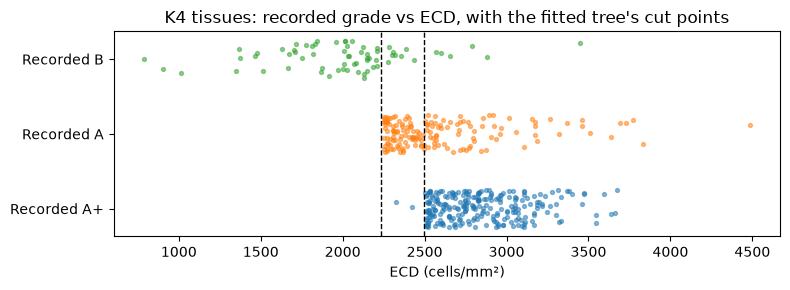

In [15]:
lower, upper = cuts["Lower cut"].median(), cuts["Upper cut"].median()
fig, ax = plt.subplots(figsize=(8, 3))
rng = np.random.default_rng(0)
for i, grade in enumerate(cs.CLASSES):
    values = k3.loc[has_ecd & (y == grade), cs.ECD]
    ax.scatter(values, np.full(len(values), i) + rng.uniform(-0.25, 0.25, len(values)), s=8, alpha=0.5)
for cut in (lower, upper):
    ax.axvline(cut, color="black", ls="--", lw=1)
    ax.annotate(f"{cut:.0f}", (cut, 2.45), ha="center", fontsize=8)
ax.set(yticks=range(3), yticklabels=[f"Recorded {g}" for g in cs.CLASSES], xlabel="ECD (cells/mm²)",
       title="K4 tissues: recorded grade vs ECD, with the fitted tree's cut points")
plt.tight_layout()
plt.show()

Per-grade precision and recall pooled over repeats: the tree calls almost every tissue above ≈2500 A+ and finds only about half of grade A; the hybrid recovers more grade A at the cost of A+ recall.

In [16]:
eval_rows = np.flatnonzero(has_ecd)
y_eval = np.tile(y[eval_rows], ms.N_REPEATS)
pooled = {arm: np.concatenate([oof[(arm, r)][eval_rows] for r in range(ms.N_REPEATS)]).astype(str) for arm in ARMS}
pooled["ECD rule"] = np.tile(rule[eval_rows], ms.N_REPEATS).astype(str)
cs.per_grade(y_eval, {m: pooled[m] for m in MODELS}).round(3)

ECD-only RF         ECD tree         ECD rule          Tabular         \
     Precision Recall Precision Recall Precision Recall Precision Recall   
A+       0.761  0.785     0.748  0.988     0.749  0.992     0.784  0.846   
A        0.594  0.558     0.884  0.528     0.894  0.528     0.676  0.599   
B        0.773  0.794     1.000  0.791     1.000  0.791     0.830  0.818   

      Hybrid         
   Precision Recall  
A+     0.809  0.890  
A      0.745  0.649  
B      0.860  0.806

## 6. Tissues without ECD (K5, descriptive)

Neither ECD-only predictor can grade these 81 tissues; the tabular and hybrid models can, but poorly.

In [17]:
no_ecd = np.flatnonzero(~has_ecd)
y_no = np.tile(y[no_ecd], ms.N_REPEATS)
pd.DataFrame({
    arm: {"Macro F1": cs.macro_f1(y_no, pred), **{f"Recall {g}": r for g, r in zip(cs.CLASSES, cs.per_grade(y_no, {arm: pred})[arm]["Recall"])}}
    for arm in ["Tabular", "Hybrid"]
    for pred in [np.concatenate([oof[(arm, r)][no_ecd] for r in range(ms.N_REPEATS)]).astype(str)]
}).T.round(3)

,Macro F1,Recall A+,Recall A,Recall B
Tabular,0.406,0.485,0.557,0.164
Hybrid,0.468,0.788,0.454,0.164


## Interpretation

- **Image on non-2023 tissues (pre-specified sensitivity, 09):** hybrid − tabular +0.038 [−0.013, +0.088], p = 0.135. **Inconclusive.** It shares tissues and folds with the exploratory result that motivated it, so it is not independent confirmation.
- **Against an ECD-only Random Forest (pre-specified, 10):** both models improved (Holm p 0.030 and 0.006). But that comparator was weak: the same ECD values support 0.796 with a two-threshold tree.
- **Against the fitted ECD tree (follow-up, 11):** tabular −0.040 and hybrid −0.007, both **inconclusive**. **Improvement beyond ECD alone was not established.**
- The tree learned cut points 2232 and 2494–2503 in every fold, close to the eye bank's rule (B below 2250, A+ from 2500): the recorded labels follow that rule's thresholds consistently, and the open question is what explains the departures from them (Hybrid 05).
- Without ECD (K5), predictions are poor (grade B recall 0.164 for both models): outputs for such tissues can only be suggestions for review.

**Limitations:** the Random Forest settings came from notebook 05 (non-grouped CV on tabular features). Hybrid 06 shows they under-tuned the tabular model by ≈0.05 macro F1, so the hybrid's apparent edge over tabular here should not be read as a benefit of images. The eye bank's 2250/2500 rule is reported descriptively, without tests; the fitted tree (learned cut points 2232 and ≈2497) is the tested ECD baseline and recovers almost the same thresholds from the labels. Multiplicity is corrected within each notebook's primary pair, not across notebooks.